Data Analysis of Restaurant Spending Patterns Using Python

Project Overview

This particular project uses "exploratory data analysis" to examine restaurant spending patterns using Python. The analysis largely focuses on transaction values, tipping behaviour, dining group sizes and differences in spending across days and meal periods.

The objective is to apply data analytics techniques that the student learnt during the course learing period at " Data Analytics With Python "  to identify patterns in consumer spending and explore relationships between numerical variables.

Research Questions

1) How does average restaurant spending vary across different days?

2) Do average bills differ between lunch and dinner?

3) Is there a relationship between total bills and tips?

4) How does dining group size relate to total spending?

Dataset

The project uses the "Tips dataset" available through the Seaborn library. It contains 244 restaurant transactions and seven variables.

In [19]:
print("Restaurant Spending Analysis")

Restaurant Spending Analysis


1. Importing Libraries

The analysis uses Python libraries for data manipulation, numerical computation and visualisation. The different Python libraries involved are:
- Pandas: Data handling and manipulation.
- NumPy:Numerical operations.
- Matplotlib: Graphical representation of data.
- Seaborn: Statistical data visualisation.


In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


2. Dataset Usage And Existing Exploration

The project uses the Tips dataset available through the Seaborn library. It contains 244 observations and seven variables related to restaurant transactions.

In [21]:

tips = sns.load_dataset("tips")
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


3. Descriptive Statistical Analysis

Descriptive statistics are used to summarise the numerical characteristics of the dataset. Measures such as mean, median, minimum and maximum values provide an overview of restaurant bills and tipping behaviour.


In [22]:

print("Dataset dimensions:", tips.shape)

print("\nDataset information:")
tips.info()

print("\nStatistical summary:")
tips.describe()

Dataset dimensions: (244, 7)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
dtypes: category(4), float64(2), int64(1)
memory usage: 7.4 KB

Statistical summary:


,total_bill,tip,size
count,244.000000,244.000000,244.000000
mean,19.785943,2.998279,2.569672
std,8.902412,1.383638,0.951100
min,3.070000,1.000000,1.000000
25%,13.347500,2.000000,2.000000
50%,17.795000,2.900000,2.000000
75%,24.127500,3.562500,3.000000
max,50.810000,10.000000,6.000000


 4. Day-wise Spending Analysis

This section examines variations in average restaurant spending across different days of the week. The dataset is grouped by day, and the mean total bill is calculated for each category. A bar chart is used to compare average transaction values and identify differences in spending patterns.

In [23]:

average_bill = tips["total_bill"].mean()


average_tip = tips["tip"].mean()

median_bill = tips["total_bill"].median()


highest_bill = tips["total_bill"].max()

print("Average bill:", round(average_bill, 2))
print("Average tip:", round(average_tip, 2))
print("Median bill:", round(median_bill, 2))
print("Highest bill:", round(highest_bill, 2))

Average bill: 19.79
Average tip: 3.0
Median bill: 17.8
Highest bill: 50.81


In [24]:

daily_spending = tips.groupby("day")["total_bill"].mean()

print(daily_spending)

day
Thur    17.682742
Fri     17.151579
Sat     20.441379
Sun     21.410000
Name: total_bill, dtype: float64


/tmp/ipykernel_1314/2593758165.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  daily_spending = tips.groupby("day")["total_bill"].mean()


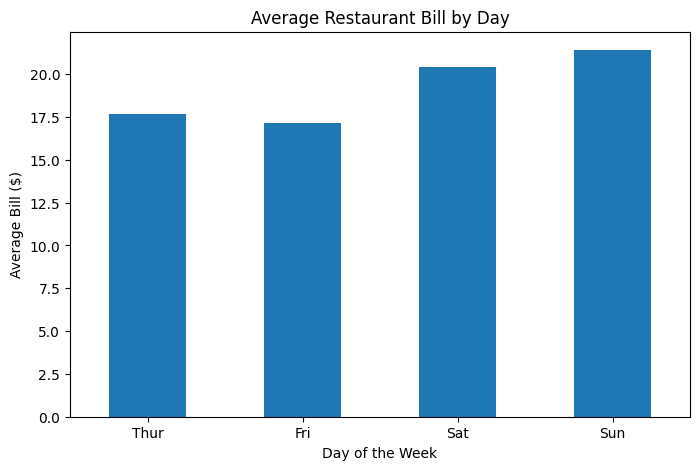

In [25]:
plt.figure(figsize=(8, 5))

daily_spending.plot(kind="bar")

plt.title("Average Restaurant Bill by Day")
plt.xlabel("Day of the Week")
plt.ylabel("Average Bill ($)")

plt.xticks(rotation=0)
plt.show()

5. Comparative Analysis between Lunch vs Dinner

This section compares average restaurant bills across two meal periods i.e lunch and dinner. The mean total bill is calculated for each category and visualised using a bar chart. The comparison helps identify differences in average transaction values between the two periods.

In [26]:

meal_spending = tips.groupby("time")["total_bill"].mean()

print(meal_spending)

time
Lunch     17.168676
Dinner    20.797159
Name: total_bill, dtype: float64


/tmp/ipykernel_1314/1302192299.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  meal_spending = tips.groupby("time")["total_bill"].mean()


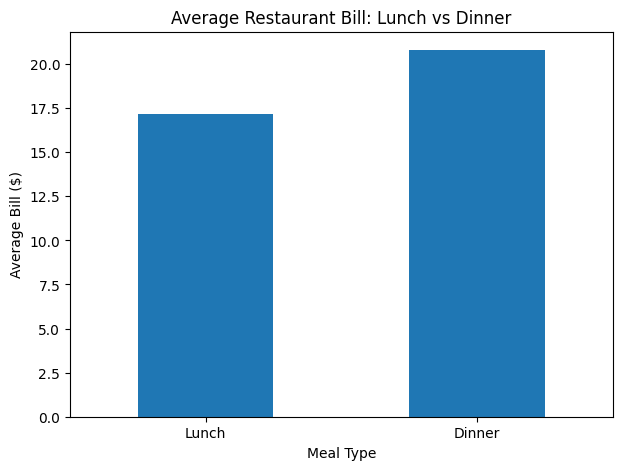

In [27]:
plt.figure(figsize=(7, 5))

meal_spending.plot(kind="bar")

plt.title("Average Restaurant Bill: Lunch vs Dinner")
plt.xlabel("Meal Type")
plt.ylabel("Average Bill ($)")

plt.xticks(rotation=0)
plt.show()

 6. Correlation Analysis ( Total Bill and Tip )

Pearson correlation analysis is used to examine the relationship between total restaurant bills and tip amounts. A correlation coefficient is calculated to measure the direction and strength of their linear association. A scatter plot is also generated to visualise the relationship and identify general patterns in the observations.

In [28]:


correlation = tips["total_bill"].corr(tips["tip"])

print("Correlation coefficient:", round(correlation, 3))

Correlation coefficient: 0.676


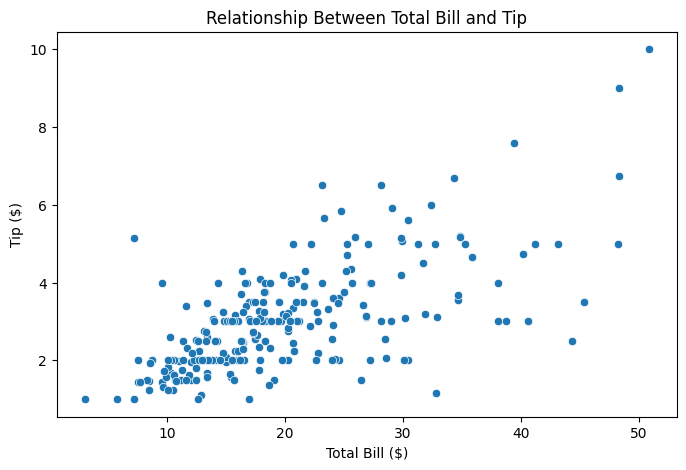

In [29]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=tips, x="total_bill", y="tip")

plt.title("Relationship Between Total Bill and Tip")
plt.xlabel("Total Bill ($)")
plt.ylabel("Tip ($)")

plt.show()

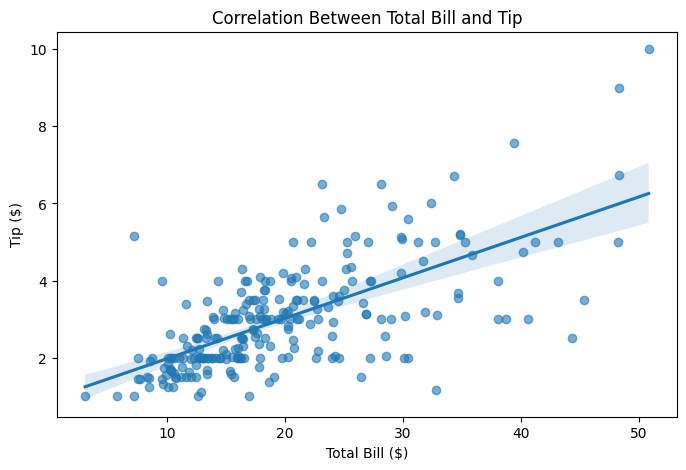

In [30]:
plt.figure(figsize=(8, 5))

sns.regplot(
    data=tips,
    x="total_bill",
    y="tip",
    scatter_kws={"alpha": 0.6}
)

plt.title("Correlation Between Total Bill and Tip")
plt.xlabel("Total Bill ($)")
plt.ylabel("Tip ($)")

plt.show()

In [31]:
print(tips["total_bill"].corr(tips["tip"]))

0.6757341092113641


7. Party Size and Restaurant Spending

This particular section investigates the relationship between dining group size and total restaurant spending. The average bill is calculated for each group size using grouping and aggregation techniques. A bar chart is used to compare average transaction values, while Pearson correlation analysis examines the association between group size and total bills.

In [32]:


party_spending = tips.groupby("size")["total_bill"].mean()

print(party_spending.round(2))

size
1     7.24
2    16.45
3    23.28
4    28.61
5    30.07
6    34.83
Name: total_bill, dtype: float64


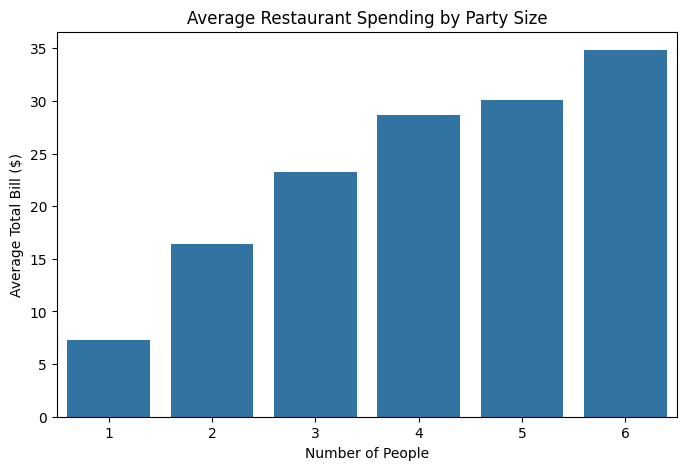

In [33]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=party_spending.index,
    y=party_spending.values
)

plt.title("Average Restaurant Spending by Party Size")
plt.xlabel("Number of People")
plt.ylabel("Average Total Bill ($)")

plt.show()

In [34]:
party_correlation = tips["size"].corr(tips["total_bill"])

print("Correlation between party size and total bill:",
      round(party_correlation, 3))

Correlation between party size and total bill: 0.598


8. Conclusion

This project demonstrates how quantitative data analysis can be used to examine patterns within everyday consumer practices. While the dataset primarily records restaurant transactions, the variables offer a small window into the relationship between consumption, social interaction and everyday life.

** A CULTURAL STUDIES PERSPECTIVE **

**By Taking The Students, Previous Undergraduate Perspective from the viewpoint of english and cultural studies:**

Taking through the theoretical aspect in " The Practice of Everyday Life ( 1984 ), by Michel de Certeau, he challenges the understanding of consumers as merely passive participants within the systems of production. He argues that consumption is also an everyday practice through which individuals use and negotiate the products and structures presented to them. Viewed from this particular theory, restaurant spending can be approached more than an economic transaction. Dining is also situated within ordinary social practices, involving shared meals, group interactions and different patterns of everyday expenditure. The observed relationship between party size and total spending offers a quantitative starting point for examining this dimesion of consumption, although the dataset cannot establish a central desginated cultural meaning behind these interactions as they are entirely individualistic and psychological in nature. However, this may be subjectively concluded in the notion that these numerical patterns in consumer transactions can be understood as a one dimension of a wider cultural context in which consumption takes place.

Although, reducing the lived experiences to data, cannot automatically nullify the human behaviour and cultural context attached to the spendings especially if viewed through the lens of comparative analysis section.


Reference For DataSet
The analysis uses the Tips dataset distributed through the Seaborn Python library.

Source: https://github.com/mwaskom/seaborn-data/blob/master/tips.csv
